# Do wavelet features help detect stock price manipulation? Evidence from enforcement cases on the IDX

Analysis notebook for the manuscript submitted to *Scientific Journal of Informatics (SJI)*.
Author: Anggit Suryopratomo (Universitas Ma'soem).

**Version 3 (5 Nov 2026):** exact OJK manipulation windows (several windows per case allowed), FILM split into its 2021 and 2023 cases, paired comparison of wavelet scores vs simple rules. Zero-volume days are kept, so illiquid stocks get scores. To reproduce the published numbers exactly, unzip `data_manip.zip` into the working folder first (the notebook then skips the download).

Run all cells in order (Runtime → Run all). All features are **causal**: the value on day *t* uses only data up to day *t*.

1. Setup and settings
2. Enforcement cases (labels)
3. Control universe and matching
4. Price and volume data
5. Causal wavelet features and anomaly scores
6. Evaluation (Tables 2–4, Figures 1–3)
7. Leakage check: two-sided (non-causal) wavelet features

## 1. Setup and settings

In [1]:
!pip install -q yfinance PyWavelets
import os, time, json, warnings
import numpy as np, pandas as pd, pywt
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, wilcoxon
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import IsolationForest
warnings.filterwarnings("ignore")

CFG = dict(
    window=128,          # causal wavelet window (trading days)
    wavelet="haar",      # shortest filter: least boundary distortion at the window end
    level=4,             # detail scales d1..d4 ~ 2-4, 4-8, 8-16, 16-32 days
    tail=8,              # energy = mean squared detail coefficients over the last `tail` days of the window
    zlen=250,            # trailing history for z-scores (strictly before t)
    pre_days=365,        # evaluation starts this many calendar days before the manipulation period
    post_days=180,       # and ends this many calendar days after it
    n_controls=5,        # matched controls per case
    fa_quantile=0.99,    # alarm threshold = this quantile of control scores in the pre-period
    min_coverage=0.90,   # controls must trade on >= 90% of case trading days
)
DATA_DIR = "data_manip"; os.makedirs(DATA_DIR, exist_ok=True)

## 2. Enforcement cases (labels)

Manipulation periods as stated in OJK sanction announcements (see manuscript, Table 1).
Rows with `exact=False` (KIOS, IMPC) were stated by month only, so whole months are used.

In [2]:
# One row per enforcement case. A case can have several manipulation windows (start, end).
# Sources: OJK sanction announcements as reported on 20 Feb, 3 Mar, 27 Mar, 16 Oct and 4 Nov 2026 (see manuscript, Table 1).
CASES = [
    # id,        ticker, windows,                                                     sanction,     exact days?
    ("PANR",    "PANR", [("2022-09-06", "2023-05-29")],                               "2026-11-04", True),
    ("FILM-21", "FILM", [("2021-01-12", "2021-12-27")],                               "2026-02-20", True),
    ("FILM-23", "FILM", [("2023-03-24", "2023-07-31")],                               "2026-03-27", True),
    ("KIOS",    "KIOS", [("2021-01-01", "2022-04-30")],                               "2026-03-27", False),  # months only
    ("SUPR",    "SUPR", [("2022-02-08", "2022-04-11")],                               "2026-03-03", True),
    ("SHID",    "SHID", [("2022-01-03", "2022-02-14")],                               "2026-01-12", True),
    ("AYLS",    "AYLS", [("2021-09-01", "2021-09-27"), ("2021-11-08", "2021-12-29")], "2026-02-20", True),
    ("BSML",    "BSML", [("2022-03-08", "2022-06-17")],                               "2026-02-20", True),
    ("IMPC",    "IMPC", [("2016-01-01", "2016-04-30")],                               "2026-02-20", False),  # months only
    ("DSSA",    "DSSA", [("2024-01-12", "2024-01-19"), ("2024-05-21", "2024-07-15"),
                         ("2024-07-18", "2026-02-03")],                               "2026-10-16", True),
]
cases = pd.DataFrame([dict(id=i, ticker=t, windows=[(pd.Timestamp(a), pd.Timestamp(b)) for a, b in w],
                           sanction=pd.Timestamp(s), exact=e) for i, t, w, s, e in CASES])
cases["start"] = cases.windows.apply(lambda w: min(a for a, _ in w))
cases["end"] = cases.windows.apply(lambda w: max(b for _, b in w))

def in_windows(index, windows):
    """Boolean mask: True on days inside any manipulation window."""
    m = np.zeros(len(index), dtype=bool)
    for a, b in windows:
        m |= (index >= a) & (index <= b)
    return m

EXCLUDE = set(cases.ticker) | {"BREN", "CUAN", "BOGA", "TRON"}   # never used as controls
cases[["id", "ticker", "start", "end", "sanction", "exact"]]

,id,ticker,start,end,sanction,exact
0,PANR,PANR,2022-09-06,2023-05-29,2026-11-04,True
1,FILM-21,FILM,2021-01-12,2021-12-27,2026-02-20,True
2,FILM-23,FILM,2023-03-24,2023-07-31,2026-03-27,True
3,KIOS,KIOS,2021-01-01,2022-04-30,2026-03-27,False
4,SUPR,SUPR,2022-02-08,2022-04-11,2026-03-03,True
5,SHID,SHID,2022-01-03,2022-02-14,2026-01-12,True
6,AYLS,AYLS,2021-09-01,2021-12-29,2026-02-20,True
7,BSML,BSML,2022-03-08,2022-06-17,2026-02-20,True
8,IMPC,IMPC,2016-01-01,2016-04-30,2026-02-20,False
9,DSSA,DSSA,2024-01-12,2026-02-03,2026-10-16,True


## 3. Control universe and matching

Upload the IDX stock list as `daftar_saham.xlsx` (or `.csv`) with a column `Kode` (download from idx.co.id → Data Pasar → Data Saham → Daftar Saham). Rename the downloaded file to `daftar_saham.xlsx`.
Sector is taken from Yahoo Finance and cached in `sector_cache.csv`.
Controls for each case: same sector, similar liquidity (mean daily traded value in the 250 trading days before the case period), full data coverage, and not in `EXCLUDE`.

In [3]:
import yfinance as yf

def load_universe(path=None):
    """Reads the IDX stock list: daftar_saham.xlsx (as downloaded from idx.co.id) or daftar_saham.csv."""
    path = path or next((p for p in ["daftar_saham.xlsx", "Daftar Saham.xlsx", "daftar_saham.csv"] if os.path.exists(p)), None)
    if path is None:
        raise FileNotFoundError("Upload the IDX stock list (daftar_saham.xlsx or .csv) to the Colab Files panel first.")
    u = pd.read_excel(path) if path.endswith(".xlsx") else pd.read_csv(path)
    col = [c for c in u.columns if c.strip().lower() in ("kode", "kode saham", "code", "ticker")][0]
    return sorted(set(u[col].astype(str).str.strip().str.upper()) - EXCLUDE)

def get_sectors(tickers, cache=os.path.join(DATA_DIR, "sector_cache.csv")):
    known = pd.read_csv(cache, index_col=0)["sector"].to_dict() if os.path.exists(cache) else {}
    for i, t in enumerate(tickers):
        if t in known:
            continue
        try:
            known[t] = yf.Ticker(f"{t}.JK").info.get("sector", "")
        except Exception:
            known[t] = ""
        if i % 25 == 0:
            pd.Series(known, name="sector").to_csv(cache); time.sleep(1)
    pd.Series(known, name="sector").to_csv(cache)
    return known

def download(tickers, start, end):
    """Daily OHLCV. Zero-volume days (no trades) are kept: price unchanged, volume 0."""
    out = {}
    for k in range(0, len(tickers), 100):                     # download in chunks of 100
        chunk = tickers[k:k + 100]
        raw = yf.download([f"{t}.JK" for t in chunk], start=start, end=end, progress=False,
                          auto_adjust=False, group_by="ticker", threads=True)
        for t in chunk:
            try:
                df = raw[f"{t}.JK"] if isinstance(raw.columns, pd.MultiIndex) else raw
                df = df[["Open", "High", "Low", "Close", "Volume"]].dropna(subset=["Close"])
            except KeyError:
                continue
            df = df[df["Close"] > 0].copy()
            df["Volume"] = df["Volume"].clip(lower=0).fillna(0)
            if len(df):
                out[t] = df
    return out

def match_controls(case, data_case, pool_data, sectors):
    """Pick n_controls stocks in the same sector with the closest pre-period log traded value."""
    pre = data_case.loc[:case.start].tail(CFG["zlen"])
    tv_case = np.log((pre["Close"] * pre["Volume"]).mean())
    days = data_case.loc[case.start - pd.Timedelta(days=CFG["pre_days"]):
                         case.end + pd.Timedelta(days=CFG["post_days"])].index
    rows = []
    for t, df in pool_data.items():
        if sectors.get(t, "") != sectors.get(case.ticker, "") or t in EXCLUDE:
            continue
        cov = df["Close"].reindex(days).notna().mean()
        p = df.loc[:case.start].tail(CFG["zlen"])
        if cov < CFG["min_coverage"] or len(p) < 0.8 * CFG["zlen"]:
            continue
        rows.append((t, abs(np.log((p["Close"] * p["Volume"]).mean()) - tv_case), cov))
    rows = sorted(rows, key=lambda r: r[1])[: CFG["n_controls"]]
    return [r[0] for r in rows]

## 4. Price and volume data

In [4]:
def run_download():
    universe = load_universe()
    sectors = get_sectors(sorted(set(universe) | set(cases.ticker)))
    data, controls = {}, {}
    for case in cases.itertuples():
        a = case.start - pd.Timedelta(days=CFG["pre_days"] + 800)   # history for window + z-scores
        b = case.end + pd.Timedelta(days=CFG["post_days"] + 5)
        own = download([case.ticker], a, b)
        if case.ticker not in own:
            print(case.id, "no data"); continue
        same = [t for t in universe if sectors.get(t, "") == sectors.get(case.ticker, "")]
        pool = download(same, a, b)
        controls[case.id] = match_controls(case, own[case.ticker], pool, sectors)
        data[case.id] = {"case": own[case.ticker], **{t: pool[t] for t in controls[case.id]}}
        print(case.id, sectors.get(case.ticker), "controls:", controls[case.id])
    pd.to_pickle((data, controls), os.path.join(DATA_DIR, "panel.pkl"))
    return data, controls

PANEL = os.path.join(DATA_DIR, "panel.pkl")
if os.path.exists(PANEL) and set(pd.read_pickle(PANEL)[0]) >= set(cases.id):
    data, controls = pd.read_pickle(PANEL)
else:
    data, controls = run_download()      # first run: about 10-20 minutes
pd.Series(controls).to_csv("controls.csv")
print(f"Cases with data: {len(data)} of {len(cases)}")
assert len(data) > 0, "No case data downloaded - check the messages above."

ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: ARMY.JK"}}}
ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: BTEL.JK"}}}
ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: CBMF.JK"}}}
ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: COWL.JK"}}}
ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: CPRI.JK"}}}
ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: DUCK.JK"}}}
ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbo

PANR Consumer Cyclical controls: ['IMAS', 'ATAP', 'INDR', 'LPIN', 'ESTA']


ERROR:yfinance:
9 Failed downloads:
ERROR:yfinance:['INET.JK', 'CNMA.JK', 'MORA.JK', 'DATA.JK', 'VERN.JK', 'DOOH.JK', 'RAAM.JK', 'AWAN.JK', 'CHIP.JK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2017-11-04 00:00:00 -> 2022-06-30 00:00:00) (Yahoo error = "Data doesn\'t exist for startDate = 1509728400, endDate = 1656522000")')


FILM-21 Communication Services controls: ['BHIT', 'DMMX', 'ABBA', 'CENT', 'MARI']


ERROR:yfinance:
2 Failed downloads:
ERROR:yfinance:['DATA.JK', 'VERN.JK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2020-01-14 00:00:00 -> 2024-02-01 00:00:00) (Yahoo error = "Data doesn\'t exist for startDate = 1578934800, endDate = 1706720400")')


FILM-23 Communication Services controls: ['WIFI', 'BMTR', 'MNCN', 'MTEL', 'SCMA']


... (8 outputs left out)

ERROR:yfinance:
23 Failed downloads:
ERROR:yfinance:['BACH.JK', 'HYGN.JK', 'CRSN.JK', 'MHKI.JK', 'MENN.JK', 'FUTR.JK', 'KLAS.JK', 'ASLI.JK', 'CBRE.JK', 'GTRA.JK', 'MUTU.JK', 'MPXL.JK', 'BLOG.JK', 'ALII.JK', 'BDKR.JK', 'MANG.JK', 'HUMI.JK', 'LOPI.JK', 'KOKA.JK', 'KING.JK', 'LAJU.JK', 'MAHA.JK', 'MEJA.JK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2018-12-29 00:00:00 -> 2022-12-19 00:00:00) (Yahoo error = "Data doesn\'t exist for startDate = 1546016400, endDate = 1671382800")')
ERROR:yfinance:
11 Failed downloads:
ERROR:yfinance:['SOLA.JK', 'PTMP.JK', 'RANS.JK', 'SMIL.JK', 'PSAT.JK', 'WIDI.JK', 'WBSA.JK', 'PJHB.JK', 'SOUL.JK', 'VISI.JK', 'PIPA.JK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2018-12-29 00:00:00 -> 2022-12-19 00:00:00) (Yahoo error = "Data doesn\'t exist for startDate = 1546016400, endDate = 1671382800")')


BSML Industrials controls: ['IMJS', 'MCAS', 'MLIA', 'TRUK', 'DGIK']


ERROR:yfinance:
50 Failed downloads:
ERROR:yfinance:['GMFI.JK', 'KRYA.JK', 'BACH.JK', 'HYGN.JK', 'CRSN.JK', 'HELI.JK', 'MENN.JK', 'MHKI.JK', 'GTSI.JK', 'BINO.JK', 'MCAS.JK', 'FUTR.JK', 'HOPE.JK', 'KLAS.JK', 'KJEN.JK', 'ISAP.JK', 'ASLI.JK', 'CBRE.JK', 'INPS.JK', 'KUAS.JK', 'IPCC.JK', 'ELPI.JK', 'GTRA.JK', 'CASH.JK', 'ARKA.JK', 'MUTU.JK', 'FIMP.JK', 'BESS.JK', 'MTPS.JK', 'MPXL.JK', 'JAYA.JK', 'BLOG.JK', 'BPTR.JK', 'BBSS.JK', 'HATM.JK', 'ALII.JK', 'HAIS.JK', 'BDKR.JK', 'MANG.JK', 'BAUT.JK', 'IPCM.JK', 'INOV.JK', 'HUMI.JK', 'KING.JK', 'LOPI.JK', 'KOKA.JK', 'LAJU.JK', 'MAHA.JK', 'CAKK.JK', 'MEJA.JK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2012-10-23 00:00:00 -> 2016-11-01 00:00:00) (Yahoo error = "Data doesn\'t exist for startDate = 1350925200, endDate = 1477933200")')
ERROR:yfinance:
40 Failed downloads:
ERROR:yfinance:['TFAS.JK', 'TCPI.JK', 'SOLA.JK', 'RCCC.JK', 'SMKM.JK', 'PTMP.JK', 'SOSS.JK', 'TEBE.JK', 'RANS.JK', 'PADA.JK', 'SMIL.JK', 'PTDU.JK', 'SKRN.JK', '

IMPC Industrials controls: ['WINS', 'LEAD', 'TSPC', 'TOTO', 'ACST']
DSSA Energy controls: ['ARII', 'AIMS', 'SHIP', 'ICON', 'SUNI']
Cases with data: 10 of 10


## 5. Causal wavelet features and anomaly scores

Three signals per stock: log return, log volume and log high–low range.
For each day *t*, the stationary wavelet transform (Haar, 4 levels) is computed on the window *t−127…t* only.
The energy of each detail scale is the mean squared coefficient over the last 8 days of the window, and each energy is turned into a z-score against the previous 250 days (excluding *t*).

In [5]:
def signals(df):
    s = pd.DataFrame(index=df.index)
    s["ret"] = np.log(df["Close"]).diff()
    s["vol"] = np.log1p(df["Volume"])
    s["rng"] = np.log(df["High"] / df["Low"]).clip(lower=0)
    return s

def swt_energy_causal(x, window, wavelet, level, tail):
    """E[t, j] = mean(d_j^2) over the last `tail` points of window x[t-window+1 .. t]."""
    n = len(x); E = np.full((n, level), np.nan)
    for t in range(window - 1, n):
        w = x[t - window + 1: t + 1]
        if np.isnan(w).mean() > 0.3:
            continue
        w = pd.Series(w).interpolate(limit_direction="both").values
        w = w - w.mean()
        coeffs = pywt.swt(w, wavelet, level=level, trim_approx=True, norm=True)
        # trim_approx=True returns [cA_level, cD_level, ..., cD_1]
        for j in range(level):
            d = coeffs[level - j]                     # j=0 -> finest detail d1
            E[t, j] = np.mean(d[-tail:] ** 2)
    return E

def swt_energy_twosided(x, wavelet, level, tail):
    """Non-causal benchmark: one transform on the whole series (uses future data)."""
    n = len(x); m = 2 ** level
    pad = (-n) % m
    w = pd.Series(x).interpolate(limit_direction="both").values
    w = np.pad(w - np.nanmean(w), (0, pad), mode="symmetric")
    coeffs = pywt.swt(w, wavelet, level=level, trim_approx=True, norm=True)
    E = np.full((n, level), np.nan)
    for j in range(level):
        d2 = pd.Series(coeffs[level - j][:n] ** 2)
        E[:, j] = d2.rolling(tail, center=True, min_periods=1).mean().values
    return E

def trailing_z(a, zlen):
    s = pd.DataFrame(a)
    mu = s.shift(1).rolling(zlen, min_periods=int(0.6 * zlen)).mean()
    sd = s.shift(1).rolling(zlen, min_periods=int(0.6 * zlen)).std()
    return ((s - mu) / sd).values

def features(df, causal=True):
    s = signals(df); out = {}
    for name in ["ret", "vol", "rng"]:
        x = s[name].values
        E = (swt_energy_causal(x, CFG["window"], CFG["wavelet"], CFG["level"], CFG["tail"]) if causal
             else swt_energy_twosided(x, CFG["wavelet"], CFG["level"], CFG["tail"]))
        Z = trailing_z(np.log(E + 1e-12), CFG["zlen"])
        for j in range(CFG["level"]):
            out[f"z_{name}_d{j+1}"] = Z[:, j]
    f = pd.DataFrame(out, index=df.index)
    # simple benchmarks (all trailing)
    v = df["Volume"]; r = s["ret"]
    f["b_volratio"] = trailing_z(np.log1p(v / v.shift(1).rolling(20).mean().replace(0, np.nan)).values[:, None], CFG["zlen"])[:, 0]
    f["b_vol20"] = trailing_z(r.rolling(20).std().values[:, None], CFG["zlen"])[:, 0]
    f["b_cum20"] = trailing_z(r.rolling(20).sum().values[:, None], CFG["zlen"])[:, 0]
    return f

def scores(f):
    sc = pd.DataFrame(index=f.index)
    short = lambda n: f[[f"z_{n}_d1", f"z_{n}_d2"]].mean(axis=1)
    sc["W_pump"] = np.minimum(short("vol"), short("ret"))       # volume AND price bursts together
    long_ = lambda n: f[[f"z_{n}_d3", f"z_{n}_d4"]].mean(axis=1)
    sc["W_long"] = np.minimum(long_("vol"), long_("ret"))       # slower ramps (8-32 days), exploratory
    sc["W_mean"] = f[[c for c in f if c.startswith("z_")]].mean(axis=1)
    sc["B_volratio"] = f["b_volratio"]
    sc["B_vol20"] = f["b_vol20"]
    sc["B_cum20"] = f["b_cum20"]
    return sc

def add_iforest(sc, f, fit_until):
    """Isolation Forest on wavelet z-features, fitted only on days before `fit_until`."""
    cols = [c for c in f if c.startswith("z_") and f[c].notna().mean() > 0.5]
    X = f[cols]; ok = X.notna().all(axis=1) & np.isfinite(X).all(axis=1)
    train = X[ok & (X.index < fit_until)]
    sc["W_iforest"] = np.nan
    if len(train) >= 100:
        m = IsolationForest(n_estimators=300, random_state=0).fit(train)
        sc.loc[ok, "W_iforest"] = -m.score_samples(X[ok])
    return sc

SCORE_COLS = ["W_pump", "W_long", "W_mean", "W_iforest", "B_volratio", "B_vol20", "B_cum20"]

def build_scores(data, causal=True):
    allsc = {}
    for case in cases.itertuples():
        if case.id not in data:
            continue
        allsc[case.id] = {}
        for name, df in data[case.id].items():
            f = features(df, causal=causal)
            sc = add_iforest(scores(f), f, fit_until=case.start - pd.Timedelta(days=CFG["pre_days"]))
            allsc[case.id][name] = sc
    return allsc

allsc = build_scores(data)

## 6. Evaluation

* **Table 2 – within-stock AUC:** can the score separate manipulation-period days from the stock's own non-manipulation days?
* **Table 3 – case vs controls:** percentile rank of the case stock's mean score among its controls during the manipulation period; across cases, a one-sided Wilcoxon test of rank > 0.5.
* **Table 4 – early detection:** threshold = 99th percentile of control scores in the pre-period; days from period start to the first alarm, and the false-alarm rate of controls over the same calendar window.

table2_auc


score,W_pump,W_long,W_mean,W_iforest,B_volratio,B_vol20,B_cum20
ticker,,,,,,,
AYLS,0.436,0.252,0.460,NaN,0.602,0.836,0.811
BSML,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DSSA,0.205,0.346,0.345,0.590,0.563,0.422,0.502
FILM-21,0.577,0.577,0.550,NaN,0.487,0.577,0.478
FILM-23,0.754,0.721,0.821,0.629,0.509,0.865,0.853
IMPC,0.341,0.570,0.572,NaN,0.404,0.204,0.459
KIOS,0.440,0.473,0.411,0.719,0.578,0.417,0.360
PANR,0.571,0.346,0.444,0.592,0.475,0.565,0.746
SHID,0.307,0.259,0.702,0.841,0.513,0.801,0.691


table3_rank


,ticker,score,mean_case,mean_controls,rank,n_controls
0,PANR,W_pump,-0.361,-0.707,0.80,5
1,PANR,W_long,-0.759,-0.717,0.40,5
2,PANR,W_mean,-0.175,-0.261,0.60,5
3,PANR,W_iforest,0.497,0.466,1.00,3
4,PANR,B_volratio,-0.012,0.012,0.40,5
...,...,...,...,...,...,...
65,DSSA,W_mean,-0.137,-0.058,0.20,5
66,DSSA,W_iforest,0.474,0.481,0.25,4
67,DSSA,B_volratio,0.024,0.036,0.80,5
68,DSSA,B_vol20,0.177,0.085,0.60,5


table4_detection


,ticker,score,threshold,days_to_first_alarm,alarm_rate_case,alarm_rate_controls
0,PANR,W_pump,1.334,NaN,0.000,0.021
1,PANR,W_long,1.425,NaN,0.000,0.016
2,PANR,W_mean,1.729,NaN,0.000,0.017
3,PANR,W_iforest,0.611,0.0,0.011,0.008
4,PANR,B_volratio,3.294,181.0,0.011,0.017
...,...,...,...,...,...,...
65,DSSA,W_mean,1.774,NaN,0.000,0.001
66,DSSA,W_iforest,0.660,NaN,0.000,0.000
67,DSSA,B_volratio,3.713,131.0,0.012,0.008
68,DSSA,B_vol20,3.757,NaN,0.000,0.004


summary


,score,AUC_mean,AUC_median,p_AUC>0.5,rank_mean,p_rank>0.5,cases_detected,median_days_to_alarm,alarm_rate_case,alarm_rate_controls
0,W_pump,0.465,0.440,0.715,0.540,0.393,4,12.0,0.028,0.021
1,W_long,0.472,0.473,0.715,0.380,0.833,2,61.0,0.010,0.014
2,W_mean,0.547,0.550,0.248,0.565,0.271,3,6.0,0.013,0.019
3,W_iforest,0.654,0.610,0.016,0.465,0.603,2,22.5,0.001,0.024
4,B_volratio,0.509,0.509,0.410,0.615,0.212,7,14.0,0.017,0.015
5,B_vol20,0.602,0.577,0.150,0.605,0.227,1,10.0,0.005,0.010
6,B_cum20,0.614,0.625,0.082,0.720,0.042,5,9.0,0.061,0.014


paired_comparison


,wavelet,rule,n_cases,mean_AUC_diff,p_wilcoxon
0,W_pump,B_volratio,9,-0.044,0.570
1,W_pump,B_vol20,9,-0.136,0.203
2,W_pump,B_cum20,9,-0.148,0.039
3,W_long,B_volratio,9,-0.037,0.652
4,W_long,B_vol20,9,-0.130,0.164
5,W_long,B_cum20,9,-0.142,0.164
6,W_mean,B_volratio,9,0.038,0.570
7,W_mean,B_vol20,9,-0.055,0.098
8,W_mean,B_cum20,9,-0.067,0.570
9,W_iforest,B_volratio,6,0.139,0.031


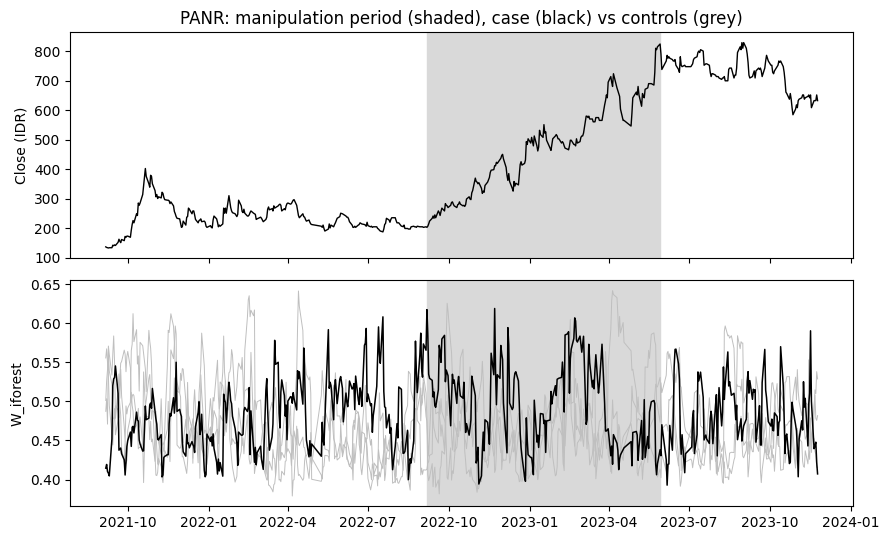

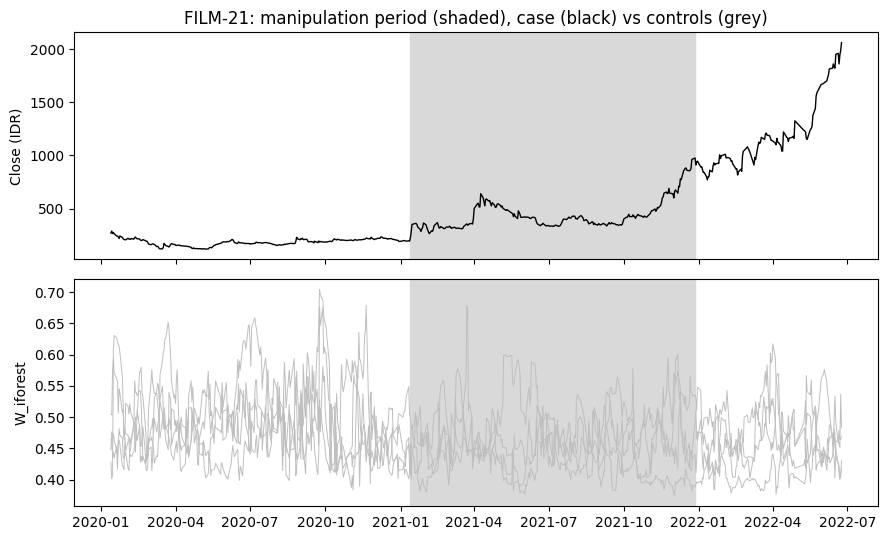

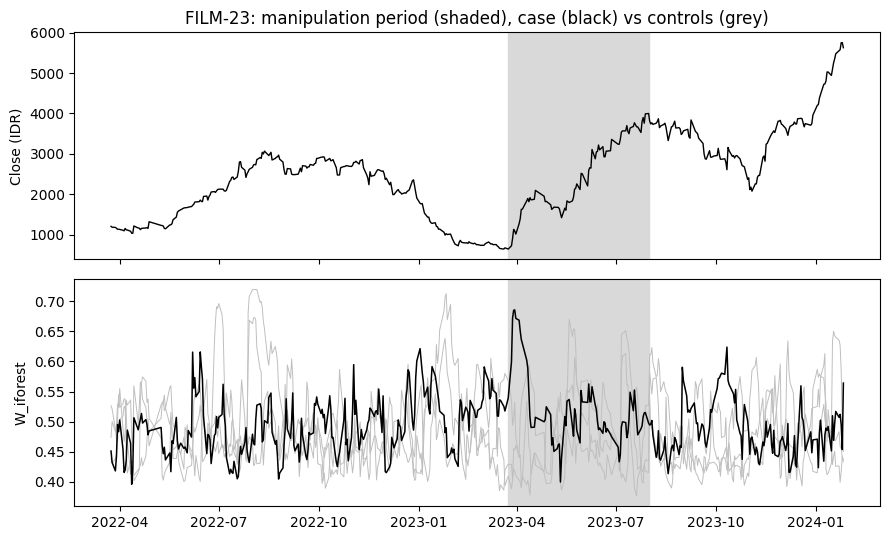

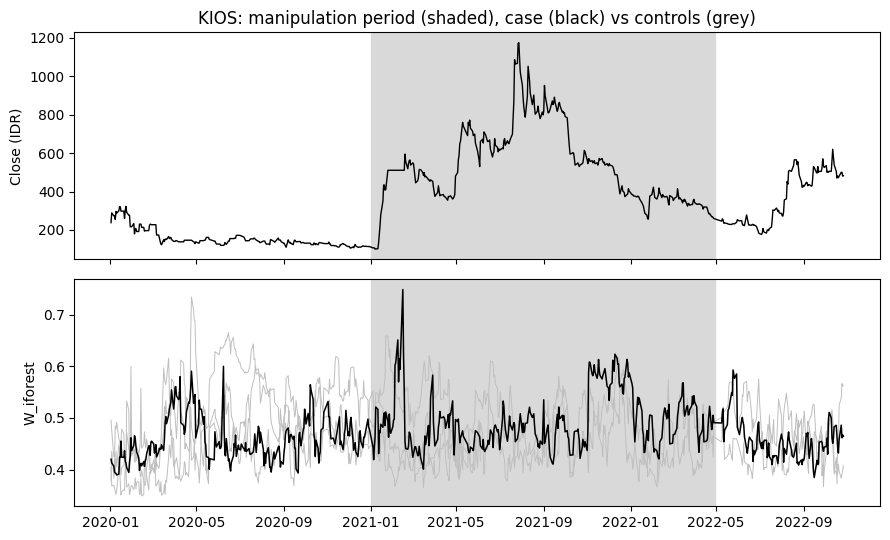

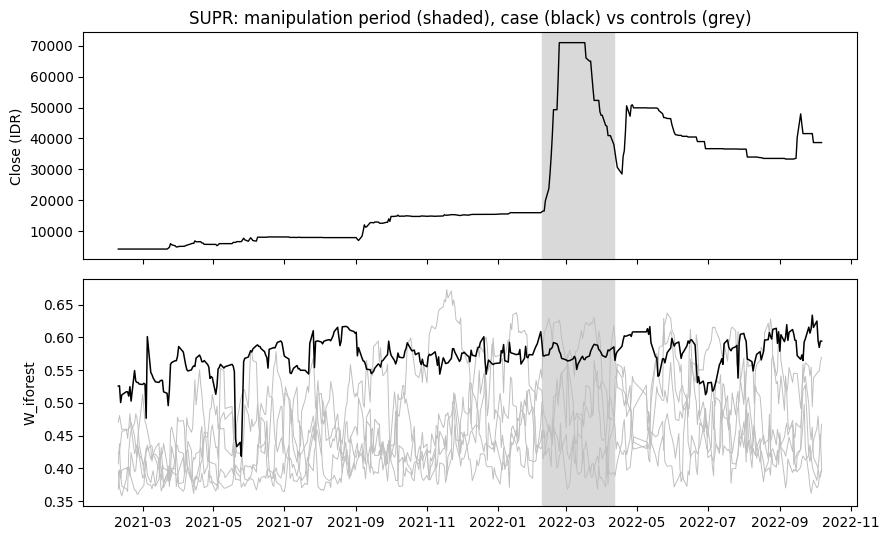

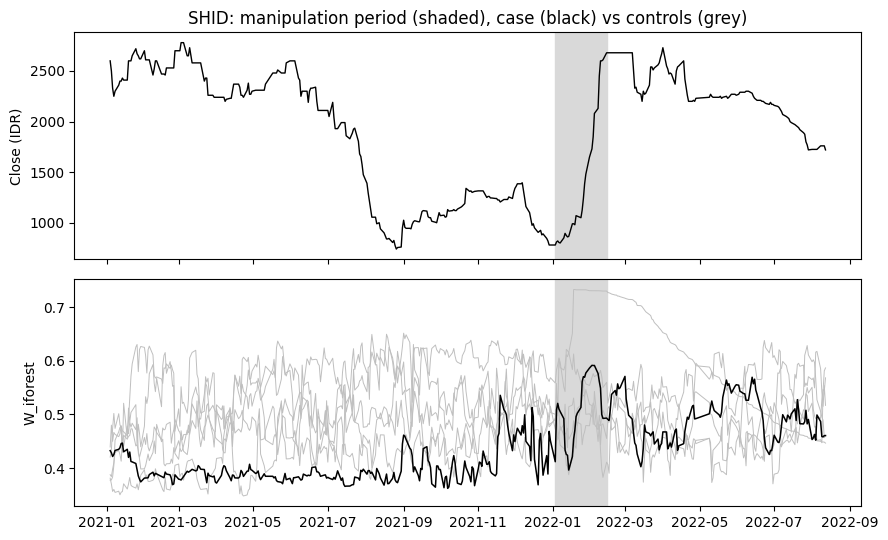

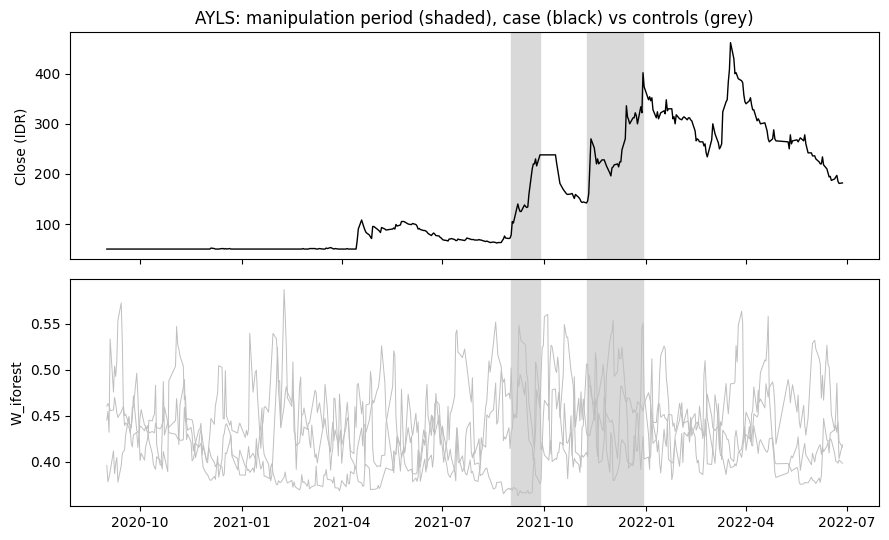

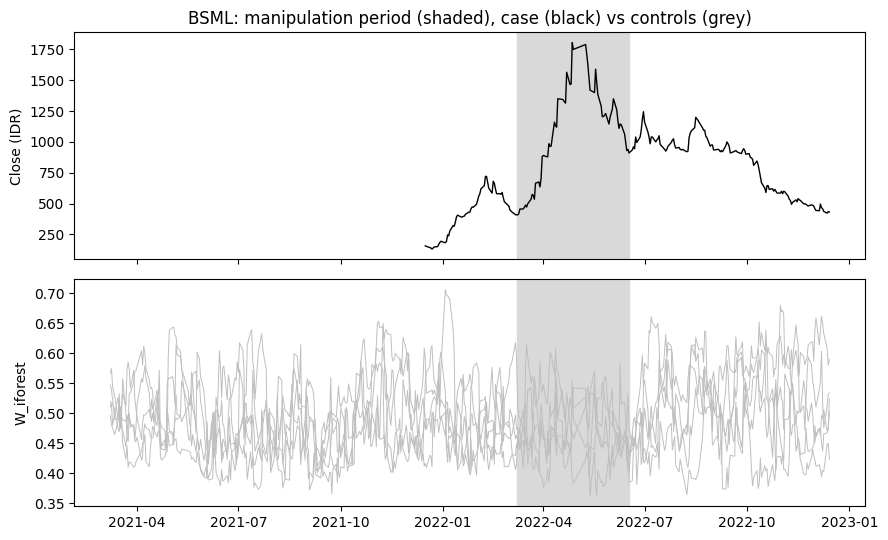

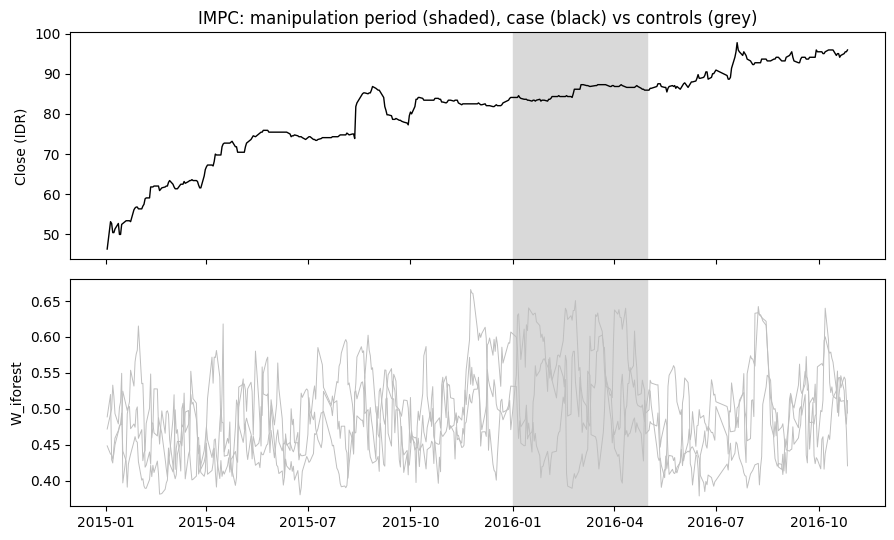

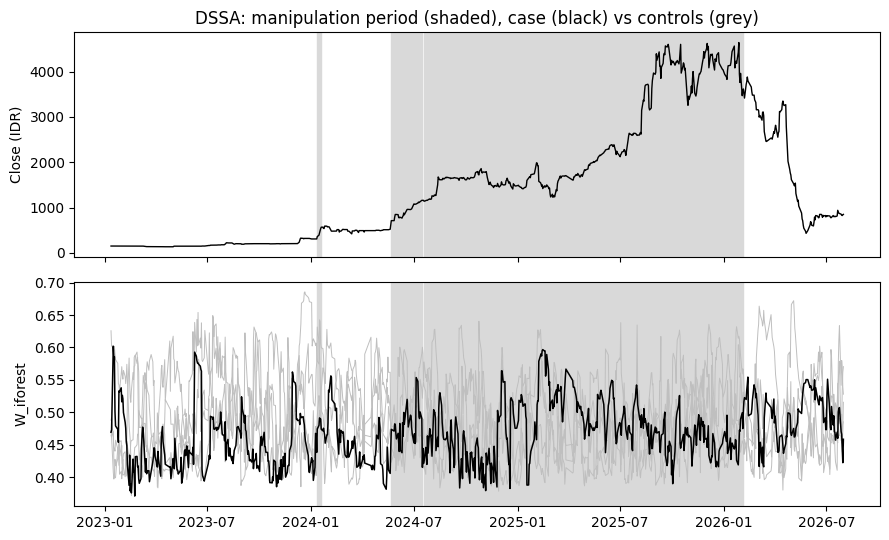

In [6]:
def evaluate(allsc):
    rows_auc, rows_rank, rows_det = [], [], []
    for case in cases.itertuples():
        if case.id not in allsc:
            continue
        S = allsc[case.id]
        a = case.start - pd.Timedelta(days=CFG["pre_days"]); b = case.end + pd.Timedelta(days=CFG["post_days"])
        cs = S["case"].loc[a:b]
        lab = in_windows(cs.index, case.windows).astype(int)
        ctrl = {k: v.loc[a:b] for k, v in S.items() if k != "case"}
        for col in SCORE_COLS:
            y = cs[col]; ok = y.notna().values
            auc = roc_auc_score(lab[ok], y.values[ok]) if 0 < lab[ok].sum() < ok.sum() else np.nan
            rows_auc.append((case.id, col, auc))
            # case vs controls in the manipulation period
            per = lambda s: s[col].loc[a:b][in_windows(s.loc[a:b].index, case.windows)].mean()
            m_case = per(S["case"]); m_ctrl = [per(v) for v in ctrl.values()]
            m_ctrl = [m for m in m_ctrl if np.isfinite(m)]
            rank = (np.sum(np.array(m_ctrl) < m_case) + 0.5 * np.sum(np.array(m_ctrl) == m_case)) / max(len(m_ctrl), 1)
            rows_rank.append((case.id, col, m_case, np.mean(m_ctrl) if m_ctrl else np.nan, rank, len(m_ctrl)))
            # early detection
            pre_ctrl = pd.concat([v[col].loc[a:case.start - pd.Timedelta(days=1)] for v in ctrl.values()]) if ctrl else pd.Series(dtype=float)
            thr = pre_ctrl.quantile(CFG["fa_quantile"]) if pre_ctrl.notna().sum() > 50 else np.nan
            inside = cs[col][lab.astype(bool)]
            hit = inside[inside > thr]
            delay = (hit.index[0] - case.start).days if len(hit) else np.nan
            post_ctrl = pd.concat([v[col][in_windows(v.index, case.windows)] for v in ctrl.values()]) if ctrl else pd.Series(dtype=float)
            fa = (post_ctrl > thr).mean() if post_ctrl.notna().sum() else np.nan
            rows_det.append((case.id, col, thr, delay, (inside > thr).mean(), fa))
    t2 = pd.DataFrame(rows_auc, columns=["ticker", "score", "auc"]).pivot(index="ticker", columns="score", values="auc")[SCORE_COLS]
    t3 = pd.DataFrame(rows_rank, columns=["ticker", "score", "mean_case", "mean_controls", "rank", "n_controls"])
    t4 = pd.DataFrame(rows_det, columns=["ticker", "score", "threshold", "days_to_first_alarm", "alarm_rate_case", "alarm_rate_controls"])
    return t2, t3, t4

def summarize(t2, t3, t4):
    s = []
    for col in SCORE_COLS:
        auc = t2[col].dropna(); rk = t3.loc[t3.score == col, "rank"].dropna()
        p_rank = wilcoxon(rk - 0.5, alternative="greater").pvalue if len(rk) >= 5 and (rk != 0.5).any() else np.nan
        p_auc = wilcoxon(auc - 0.5, alternative="greater").pvalue if len(auc) >= 5 and (auc != 0.5).any() else np.nan
        d = t4[t4.score == col]
        s.append((col, auc.mean(), auc.median(), p_auc, rk.mean(), p_rank,
                  d["days_to_first_alarm"].notna().sum(), d["days_to_first_alarm"].median(),
                  d["alarm_rate_case"].mean(), d["alarm_rate_controls"].mean()))
    return pd.DataFrame(s, columns=["score", "AUC_mean", "AUC_median", "p_AUC>0.5", "rank_mean", "p_rank>0.5",
                                    "cases_detected", "median_days_to_alarm", "alarm_rate_case", "alarm_rate_controls"])

def figures(allsc, data, ticker, col="W_iforest", fname=None):
    case = cases.set_index("id").loc[ticker]
    a = case.start - pd.Timedelta(days=CFG["pre_days"]); b = case.end + pd.Timedelta(days=CFG["post_days"])
    S = allsc[ticker]; px = data[ticker]["case"].loc[a:b]
    fig, ax = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
    ax[0].plot(px.index, px["Close"], color="black", lw=1); ax[0].set_ylabel("Close (IDR)")
    for k, v in S.items():
        if k != "case":
            ax[1].plot(v.loc[a:b].index, v[col].loc[a:b], color="0.75", lw=0.7)
    ax[1].plot(S["case"].loc[a:b].index, S["case"][col].loc[a:b], color="black", lw=1.1)
    for x in ax:
        for wa, wb in case.windows:
            x.axvspan(wa, wb, color="0.85", zorder=0)
    ax[1].set_ylabel(col); ax[0].set_title(f"{ticker}: manipulation period (shaded), case (black) vs controls (grey)")
    fig.tight_layout()
    if fname:
        fig.savefig(fname, dpi=300)
    return fig

t2, t3, t4 = evaluate(allsc); summary = summarize(t2, t3, t4)
for name, t in [("table2_auc", t2), ("table3_rank", t3), ("table4_detection", t4), ("summary", summary)]:
    t.to_csv(f"{name}.csv"); print(name); display(t.round(3))
for tk in allsc:
    figures(allsc, data, tk, fname=f"fig_{tk}.png")

# Paired comparison: each wavelet score vs each simple rule, on cases where both AUCs exist
pairs = []
for w in ["W_pump", "W_long", "W_mean", "W_iforest"]:
    for bcol in ["B_volratio", "B_vol20", "B_cum20"]:
        d = (t2[w] - t2[bcol]).dropna()
        p = wilcoxon(d).pvalue if len(d) >= 5 and (d != 0).any() else np.nan
        pairs.append((w, bcol, len(d), d.mean(), p))
paired = pd.DataFrame(pairs, columns=["wavelet", "rule", "n_cases", "mean_AUC_diff", "p_wilcoxon"])
paired.to_csv("paired_comparison.csv", index=False); print("paired_comparison"); display(paired.round(3))

## 7. Leakage check: two-sided wavelet features

Repeats the evaluation with one wavelet transform on the whole series, the common but non-causal practice.
A higher AUC here than in Section 6 shows how much look-ahead bias would inflate the results.

In [7]:
allsc_2s = build_scores(data, causal=False)
t2s, t3s, t4s = evaluate(allsc_2s); summary_2s = summarize(t2s, t3s, t4s)
summary_2s.to_csv("summary_twosided.csv"); display(summary_2s.round(3))

,score,AUC_mean,AUC_median,p_AUC>0.5,rank_mean,p_rank>0.5,cases_detected,median_days_to_alarm,alarm_rate_case,alarm_rate_controls
0,W_pump,0.536,0.514,0.326,0.555,0.422,5,13.0,0.030,0.032
1,W_long,0.517,0.572,0.410,0.485,0.559,5,7.0,0.057,0.022
2,W_mean,0.563,0.544,0.213,0.585,0.271,4,14.5,0.038,0.023
3,W_iforest,0.504,0.460,0.656,0.485,0.578,2,15.5,0.004,0.010
4,B_volratio,0.509,0.509,0.410,0.615,0.212,7,14.0,0.017,0.015
5,B_vol20,0.602,0.577,0.150,0.605,0.227,1,10.0,0.005,0.010
6,B_cum20,0.614,0.625,0.082,0.720,0.042,5,9.0,0.061,0.014
